# Preprocessing tabular data with one pipeline

This notebook is a practical template for preprocessing tabular data.

The central idea is to define **one pipeline** and reuse it consistently:
- on the training data, where the preprocessing is fitted;
- on future data, where the same fitted preprocessing is applied again.

We do this because the model will eventually be used on new, unseen data. The same exactp processing is to be done on the training data and the future data to ensure the data is mapped to the same feature space.

This notebook shows:
- Data inspection
- Feature engineering
- Missing value handling (realistic)
- Categorical encoding
- Numerical scaling
- One pipeline applied consistently


## 0. Setup and imports

Libraries used in this notebook include:
- `numpy` and `pandas` for data manipulation;
- `matplotlib` for visualization;
- `sklearn` for building the preprocessing pipeline.

Installation with conda:
```bash
conda create -n ml python=3.10
conda activate ml
conda install numpy pandas matplotlib scikit-learn
```


In [ ]:
# Imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

## 1. Load the data
We start by loading the data.
In our case, we hardcode the raw data.
Instead of this, you would typically load the data from a file or a database, using `pd.read_csv()` or similar functions.
This raw table will be used for inspection, while all preprocessing is done in a separate pipeline.

In [2]:
# Data

raw_df = pd.DataFrame(
    [
        [1,  "Mon", "local",     "bad",   12, "delayed"],
        [2,  "Mon", "express",   "good",   0, "on-time"],
        [3,  "Sat", "local",     "bad",   20, "delayed"],
        [4,  "Sun", "express",   "good",   3, "on-time"],
        [5,  "Fri", "local",     "foggy",  2, "on-time"],
        [6,  "Fri", "intercity", "foggy",  8, "delayed"],
        [7,  "Thu", "local",     "bad",   14, "delayed"],
        [8,  "Thu", "intercity", "good",   2, "on-time"],
        [9,  "Fri", "local",     "good",   6, "delayed"],
        [10, "Wed", "express",   "bad",   10, "on-time"],
    ],
    columns=["Id", "Date", "Route", "Weather", "Inbound delay", "Status"],
)

# .head() shows the first few rows and is a quick way to inspect the table.
raw_df.head()

,Id,Date,Route,Weather,Inbound delay,Status
0,1,Mon,local,bad,12,delayed
1,2,Mon,express,good,0,on-time
2,3,Sat,local,bad,20,delayed
3,4,Sun,express,good,3,on-time
4,5,Fri,local,foggy,2,on-time


## 2. Inspect the raw data

We first inspect the data.
We look at the whole table, summarize numerical and categorical columns separately, and inspect the target values.

Separating the target from the features early is crucial to prevent data leakage during preprocessing.

`Id` is an identifier, so we drop it from the features and keep it only for inspection. We will not use it in the pipeline.

In [3]:
# Basic size information.
print("Shape:", raw_df.shape)

# .head() shows the first rows.
display(raw_df.head())

# Separate features and target, but keep the original data frame unchanged.
X_raw = raw_df.drop(columns="Status")
y_raw = raw_df["Status"]

# Identify numerical and categorical columns.
numeric_cols = ["Inbound delay"]
categorical_cols = ["Date", "Route", "Weather"]

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Shape: (10, 6)


,Id,Date,Route,Weather,Inbound delay,Status
0,1,Mon,local,bad,12,delayed
1,2,Mon,express,good,0,on-time
2,3,Sat,local,bad,20,delayed
3,4,Sun,express,good,3,on-time
4,5,Fri,local,foggy,2,on-time


Numerical columns: ['Inbound delay']
Categorical columns: ['Date', 'Route', 'Weather']


### 2.1 Numerical features

Use `.describe()` on numerical columns to see count, mean, standard deviation, minimum, quartiles, and maximum.


In [4]:
# .describe() summarizes numerical columns with descriptive statistics.
X_raw[numeric_cols].describe()

,Inbound delay
count,10.000000
mean,7.700000
std,6.360468
min,0.000000
25%,2.250000
50%,7.000000
75%,11.500000
max,20.000000


### 2.2 Categorical features

For categorical columns, `.describe()` reports quantities such as the number of distinct values and the most frequent value.


In [5]:
# .describe(include="object") summarizes categorical/string columns.
X_raw[categorical_cols].describe()

,Date,Route,Weather
count,10,10,10
unique,6,3,3
top,Fri,local,bad
freq,3,5,4


### 2.3 Target values

It is useful to check the class labels and their frequencies early.


In [6]:
# .value_counts() counts how often each target label appears.
y_raw.value_counts()

Status
delayed    5
on-time    5
Name: count, dtype: int64

### 2.4 Histograms before transformation

We plot the numerical feature that we intend to transform.
The identifier `Id` is not a meaningful measurement, so we do not plot it as a feature distribution.


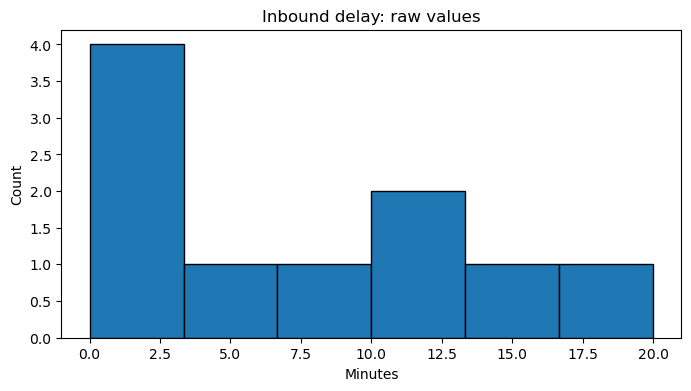

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(X_raw["Inbound delay"], bins=6, edgecolor="black")
ax.set_title("Inbound delay: raw values")
ax.set_xlabel("Minutes")
ax.set_ylabel("Count")
plt.show()

## 3. Define preprocessing as a pipeline

We now define **one pipeline** that contains all preprocessing steps.

At a high level, the pipeline will:
1. create the engineered features,
2. handle missing values (median for numerical, most frequent for categorical),
3. transform the numerical feature (log and standardization),
4. encode the route categories,
5. return the final modeling table in a fixed column order.

Keeping these steps inside one pipeline is important because the same fitted transformation must later be applied to new data.

### 3.1 Feature engineering inside the pipeline

The custom transformer below performs the hand-crafted feature transformations:
- `Date` becomes `Weekend` with values `0` or `1`;
- `Weather` becomes `Weather_unfavourable` with values `0` or `1`;;
- the raw columns `Date` and `Weather` are removed from the modeling table.

The original raw table remains unchanged; only the copy inside the pipeline is transformed.


In [8]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    '''Custom transformer for hand-crafted feature engineering.'''
    def fit(self, X, y=None):
        # No parameters are learned here, so fit simply returns self.
        return self

    def transform(self, X):
        X = X.copy()   # Avoid modifying the original data frame.

        # Weekend is engineered from the raw Date column.
        X["Weekend"] = X["Date"].isin(["Sat", "Sun"]).astype(int)

        # Weather is simplified into one binary feature.
        # bad and foggy are treated as unfavourable conditions.
        X["Weather_adverse"] = X["Weather"].isin(["bad", "foggy"]).astype(int)

        # Remove the raw columns that were replaced by engineered features.
        X = X.drop(columns=["Date", "Weather"])

        return X

feature_engineer = FeatureEngineer()

# Preview the engineered table before any scaling or encoding.
feature_engineer.transform(X_raw).head()

,Id,Route,Inbound delay,Weekend,Weather_adverse
0,1,local,12,0,1
1,2,express,0,0,0
2,3,local,20,1,1
3,4,express,3,1,0
4,5,local,2,0,1


### 3.2 Handling missing values

Before scaling and encoding, we handle missing values separately for each data type:

**Numerical features**: Missing values filled with the median (learned from training data).

**Categorical features**: Missing values filled with the most frequent category (learned from training data).

Both strategies are applied during training and later reused identically on future data.

### 3.3 Numerical transformation

For the feature `Inbound delay` we apply:
1. log transformation: $\log(1+x)$;
2. standardization.

`np.log1p(x)` is used instead of `np.log(x)` because it safely handles zero:
- `np.log(0)` is undefined,
- `np.log1p(0) = 0`.

This is useful for delay data, where small differences near zero can matter more than equally sized differences among large delays.

In [ ]:
numeric_features = ["Inbound delay"]
route_feature = ["Route"]
binary_features = ["Weekend", "Weather_adverse"]

numeric_pipeline = Pipeline(
    steps=[
        # SimpleImputer fills missing values with a learned statistic (e.g., median).
        # This is applied both during training (fit_transform) and future predictions (transform).
        ("imputer", SimpleImputer(strategy="median")),
        
        # FunctionTransformer applies a NumPy function inside a scikit-learn pipeline.
        # Here, np.log1p(x) computes log(1 + x), which handles zero values safely.
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),

        # StandardScaler subtracts the mean and divides by the standard deviation.
        # This puts the transformed numerical feature on a standard scale.
        ("scaler", StandardScaler()),
    ]
)

# Categorical pipeline for handling missing values in categorical features.
categorical_pipeline = Pipeline(
    steps=[
        # SimpleImputer fills missing categorical values with the most frequent category.
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ]
)

route_encoder = OneHotEncoder(
    categories=[["local", "express", "intercity"]],
    handle_unknown="ignore",
    sparse_output=False,
    feature_name_combiner=lambda feature, category: f"{feature}_{category}",
)

preprocessor = ColumnTransformer(
    transformers=[
        # Keep the transformed features in the intended order:
        # Weekend, Route_*, Weather_adverse, Inbound delay
        ("weekend", "passthrough", ["Weekend"]),
        ("route", Pipeline([
            ("cat_pipe", categorical_pipeline),
            ("encoder", route_encoder),
        ]), route_feature),
        ("weather", "passthrough", ["Weather_adverse"]),
        ("delay", numeric_pipeline, numeric_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

full_pipeline = Pipeline(
    steps=[
        ("feature_engineering", feature_engineer),
        ("preprocess", preprocessor),
    ]
)

full_pipeline

Pipeline(steps=[('feature_engineering', FeatureEngineer()),
                ('preprocess',
                 ColumnTransformer(transformers=[('weekend', 'passthrough',
                                                  ['Weekend']),
                                                 ('route',
                                                  OneHotEncoder(categories=[['local',
                                                                             'express',
                                                                             'intercity']],
                                                                feature_name_combiner=<function <lambda> at 0x0000028D1272D510>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Route']),
                                                 ('weather', 'passthrough',
                                                  ['Weather_adverse']),
                                                 ('delay',
                                                  Pipeline(steps=[('log1p',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Inbound delay'])],
                                   verbose_feature_names_out=False))])

### 3.3 Encode the target separately

The target is not part of the preprocessing pipeline.
We encode it once as a binary label:
- `on-time -> 0`
- `delayed -> 1`

In principle, the target could also need processed, scaled, or encoded in some way.
In that case, we would define a separate pipeline for the target, and fit it on the training target values, and apply it to future target values (if available).


In [10]:
y = (y_raw == "delayed").astype(int)
y.head()

0    1
1    0
2    1
3    0
4    0
Name: Status, dtype: int32

## 4. Fit that pipeline on training data

Now we fit the preprocessing pipeline on the training data and transform the same training data into the final modeling table.


In [11]:
# fit_transform() first learns any required transformation parameters on the training data
# (for example the mean and standard deviation for standardization),
# and then applies the fitted preprocessing to that same training data.
X_train_transformed = full_pipeline.fit_transform(X_raw, y)

# The result of a pipeline is transformed data returned as a NumPy array, which does not have column names.
feature_names = full_pipeline.named_steps["preprocess"].get_feature_names_out()

X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_raw.index,
)

X_train_transformed_df.head()

,Weekend,Route_local,Route_express,Route_intercity,Weather_adverse,Inbound delay
0,0.0,1.0,0.0,0.0,1.0,0.812412
1,0.0,0.0,1.0,0.0,0.0,-2.078768
2,1.0,1.0,0.0,0.0,1.0,1.352981
3,1.0,0.0,1.0,0.0,0.0,-0.516154
4,0.0,1.0,0.0,0.0,1.0,-0.840425


### Check the new columns

The transformed features are:

1. binary: `Weekend` from `Date`
2. binary: `Route_local`, `Route_express`, `Route_intercity` from `Route`
3. binary: `Weather_adverse` from `Weather`
4. numeric: `Inbound delay` after log transformation and standardization

In [12]:
list(X_train_transformed_df.columns)

['Weekend',
 'Route_local',
 'Route_express',
 'Route_intercity',
 'Weather_adverse',
 'Inbound delay']

### Compare raw and transformed numerical values

This small table isolates the numerical transformation.


In [13]:
numeric_inspection = pd.DataFrame(
    {
        "Inbound delay": X_raw["Inbound delay"],
        # np.log1p(x) means log(1 + x), so zero stays valid.
        "log1p(Inbound delay)": np.log1p(X_raw["Inbound delay"]),
        "Pipeline output": X_train_transformed_df["Inbound delay"],
    }
)

numeric_inspection

,Inbound delay,log1p(Inbound delay),Pipeline output
0,12,2.564949,0.812412
1,0,0.000000,-2.078768
2,20,3.044522,1.352981
3,3,1.386294,-0.516154
4,2,1.098612,-0.840425
5,8,2.197225,0.397917
6,14,2.708050,0.973713
7,2,1.098612,-0.840425
8,6,1.945910,0.114638
9,10,2.397895,0.624111


### Histograms after transformation

We again inspect the delay feature, now after the pipeline has transformed it.


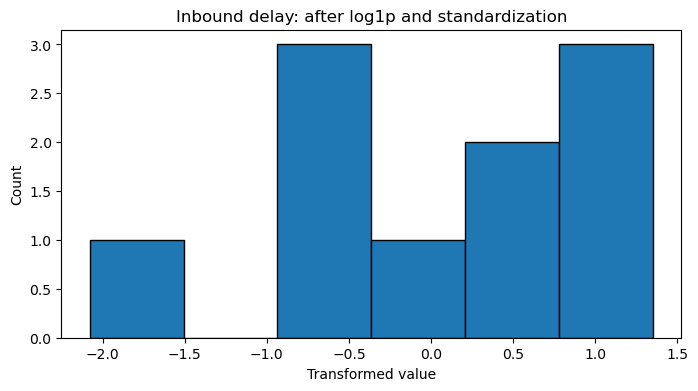

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(X_train_transformed_df["Inbound delay"], bins=6, edgecolor="black")
ax.set_title("Inbound delay: after log1p and standardization")
ax.set_xlabel("Transformed value")
ax.set_ylabel("Count")
plt.show()

### Final modeling table

This is the table that would be passed to a machine learning algorithm.


In [15]:
modeling_df = X_train_transformed_df.copy()
modeling_df["Status"] = y.values
modeling_df.head(10)

,Weekend,Route_local,Route_express,Route_intercity,Weather_adverse,Inbound delay,Status
0,0.0,1.0,0.0,0.0,1.0,0.812412,1
1,0.0,0.0,1.0,0.0,0.0,-2.078768,0
2,1.0,1.0,0.0,0.0,1.0,1.352981,1
3,1.0,0.0,1.0,0.0,0.0,-0.516154,0
4,0.0,1.0,0.0,0.0,1.0,-0.840425,0
5,0.0,0.0,0.0,1.0,1.0,0.397917,1
6,0.0,1.0,0.0,0.0,1.0,0.973713,1
7,0.0,0.0,0.0,1.0,0.0,-0.840425,0
8,0.0,1.0,0.0,0.0,0.0,0.114638,1
9,0.0,0.0,1.0,0.0,1.0,0.624111,0


## 5. Apply the same fitted pipeline to future data

The point of using **one pipeline** is that future data must go through exactly the same fitted preprocessing.
We do **not** redesign the transformations for the new data.
We reuse the pipeline that was fitted on the training data.


In [16]:
application_df = pd.DataFrame(
    [
        [11, "Tue", "local",     "good",   4],
        [12, "Sat", "intercity", "foggy", 11],
        [13, "Wed", "express",   "good",   1],
        [14, "Sun", "local",     "bad",   16],
    ],
    columns=["Id", "Date", "Route", "Weather", "Inbound delay"],
)

# Keep the future/application data raw as well.
application_df.head()

,Id,Date,Route,Weather,Inbound delay
0,11,Tue,local,good,4
1,12,Sat,intercity,foggy,11
2,13,Wed,express,good,1
3,14,Sun,local,bad,16


Important: We call `pipeline.transform()` on the future data, not `pipeline.fit_transform()`.

The future data must have the same raw columns as the training data, and the same column names, for the pipeline to work correctly.

In [17]:
# transform() applies the already fitted preprocessing to new data.
# No new means, standard deviations, or encodings are learned here.
X_application_transformed = full_pipeline.transform(application_df)

X_application_transformed_df = pd.DataFrame(
    X_application_transformed,
    columns=feature_names,
    index=application_df.index,
)

display(application_df)
display(X_application_transformed_df)

,Id,Date,Route,Weather,Inbound delay
0,11,Tue,local,good,4
1,12,Sat,intercity,foggy,11
2,13,Wed,express,good,1
3,14,Sun,local,bad,16


,Weekend,Route_local,Route_express,Route_intercity,Weather_adverse,Inbound delay
0,0.0,1.0,0.0,0.0,0.0,-0.264629
1,1.0,0.0,0.0,1.0,1.0,0.722189
2,0.0,0.0,1.0,0.0,0.0,-1.297461
3,1.0,1.0,0.0,0.0,1.0,1.114796


## Workflow summary

The core workflow is:

1. keep the original data intact,
2. inspect the raw data,
3. define preprocessing as a pipeline,
4. fit that pipeline on training data,
5. apply the same fitted pipeline to future data.

Everything else in the notebook is a lower-level detail inside these five steps.


For production/complex scenarios:

- Have a model in mind from the start, and design the preprocessing to fit that model's assumptions and requirements.
- Missing value handling — Add an imputer step before scaling
- Feature interactions — Use PolynomialFeatures if needed
- Box-Cox/Yeo-Johnson — Alternative to log1p for non-normal distributions
- Datetime features — Extract year, month, day, day-of-week separately
- Feature selection — Add SelectKBest or RFE to reduce dimensionality